# 06 — Targeted feature experiments after error analysis

Test two focused hypotheses against the saved 30,000-term A2 logistic baseline. These are development experiments motivated by a few reviewed examples, not established fraud rules. Review more independent groups before interpreting a gain as broadly useful. The classifier, C grid, TF-IDF limit, outer folds and evaluation procedure stay fixed.

1. **A2 without explicit missing-field indicators:** remove engineered `missing_*` flags and `n_missing_fields`. Does their removal reduce false alarms enough to help? This is not removal of all missingness information: categorical MISSING levels, zero text lengths, salary indicators and empty text can still carry it.
2. **A2 plus compensation-context indicators:** add row-wise flags for currency amounts, unspecified pay periods, earning-up-to claims and commission wording. These are neutral text observations, not a rule that unclear pay is fraudulent. The original text and standard A2 features stay present.

Run with the project environment in a separate kernel. Training defaults off. Enable only one candidate at a time to isolate changes; do not combine them until the individual comparisons have been reviewed. Completed matching results are reused; unfinished candidates currently restart. No shared source files are changed.

Employer-identity inference is deferred: a simple company-name regex could mistake a client or brand for the hiring employer. Semantic embeddings belong in a separate later experiment. External employer/link verification belongs to the agent tools.

The notebook reuses 02's exact outer assignments and saved baseline scores, validating predictions. Historical inner assignments and training-time baseline provenance were not saved; that limitation remains. The reserved test set is never read.

In [6]:
import hashlib
import importlib.metadata
import json
from pathlib import Path
import sys
import tempfile
from joblib import Memory
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from threadpoolctl import threadpool_limits

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/evaluation.py').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.features import build_inputs, logistic_pipeline, FEATURE_SETS
from src.evaluation import cross_validate, validate_folds, fold_signature, score_summary, summarise, paired_comparison
import re

REPORT_DIR = ROOT / 'reports/classifier_targeted_features'
PREDICTION_DIR = ROOT / 'data/processed/classifier_targeted_features'
# Enable one candidate at a time when ready.
TRAIN_MODELS = ['a2_without_explicit_missing', 'a2_compensation_context']
# Example: TRAIN_MODELS = ['a2_without_explicit_missing']
# Other candidate: 'a2_compensation_context'
THREADS = 2
INNER_SPLITS = 3
SEED = 42
C_GRID = {'model__C': [0.1, 0.3, 1.0]}
BASELINES = {'logreg_text_30k': 'logreg_tf_idf_only', 'logreg_a2_30k': 'logreg_a2'}
CANDIDATES = ['a2_without_explicit_missing', 'a2_compensation_context']
NAMES = {'logreg_text_30k': '02: text-only logistic (30k)',
         'logreg_a2_30k': '02: A2 logistic (30k)',
         'a2_without_explicit_missing': '06: A2 without explicit missing indicators',
         'a2_compensation_context': '06: A2 plus compensation context'}

def sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

print('Training enabled for:', TRAIN_MODELS or 'none — load saved results only')

Training enabled for: ['a2_without_explicit_missing', 'a2_compensation_context']


## 1. Recover and validate notebook 02's exact outer folds

Read only training data. Match saved job IDs and group IDs, check disjoint groups, and verify every fold signature against the baseline score tables. Fail rather than silently create replacement splits.

In [7]:
train_path = ROOT / 'data/processed/d1_train.csv'
assignment_path = ROOT / 'data/processed/model_cv_assignments.csv'
train = pd.read_csv(train_path)
assert train.job_id.is_unique
X = build_inputs(train)

# Row-wise text observations; no labels or corpus statistics are used.
CONTEXT_COLUMNS = ['comp_currency_amount', 'comp_currency_without_period',
                   'comp_earning_up_to', 'comp_commission_wording']
def compensation_context(texts):
    texts = texts.fillna('').astype(str)
    money = texts.str.contains(r'[$£€]\s*\d|\b(?:USD|GBP|EUR)\s*\d', case=False, regex=True)
    # A nearby period is only a heuristic: this does not interpret contracts or verify salaries.
    period = r'(?:per\s+(?:hour|day|week|month|year|annum)|hourly|daily|weekly|monthly|annually|annual|/\s*(?:hr|hour|day|week|month|year))'
    contextual_period = texts.str.contains(
        r'(?:[$£€]\s*\d[^.!?;\n]{0,80}' + period + r'|' + period + r'[^.!?;\n]{0,80}[$£€]\s*\d)',
        case=False, regex=True)
    return pd.DataFrame({
        'comp_currency_amount': money,
        'comp_currency_without_period': money & ~contextual_period,
        'comp_earning_up_to': texts.str.contains(r'\b(?:earn|make|earning|earnings)\b[^.!?;\n]{0,40}\bup to\b', case=False, regex=True),
        'comp_commission_wording': texts.str.contains(r'\bcommission(?:s|ed)?\b', case=False, regex=True),
    }, index=texts.index).astype(float)
context_features = compensation_context(X.text_clean)
X = pd.concat([X, context_features], axis=1)
print('Compensation context prevalence (not evidence of fraud):')
display(context_features.mean().rename('share_of_ads'))
y, groups = train.fraudulent.to_numpy(), train.group_id.to_numpy()
assignments = pd.read_csv(assignment_path)
positions = pd.Series(np.arange(len(train)), index=train.job_id)
folds = []
for (repeat, fold), rows in assignments.groupby(['repeat', 'fold'], sort=True):
    if not rows.job_id.is_unique or not rows.job_id.isin(positions.index).all():
        raise ValueError('Invalid job IDs in the saved assignments.')
    val = np.sort(positions.loc[rows.job_id].to_numpy())
    saved_groups = rows.set_index('job_id').group_id
    if not np.array_equal(saved_groups.loc[train.iloc[val].job_id].to_numpy(), groups[val]):
        raise ValueError('Group IDs differ from notebook 02.')
    fit = np.setdiff1d(np.arange(len(train)), val)
    folds.append((int(repeat), int(fold), fit, val))
folds = validate_folds(folds, y, groups)
expected = {(r, f): fold_signature(y, groups, fit, val) for r, f, fit, val in folds}

def validate_scores(scores):
    if scores.duplicated(['repeat', 'fold']).any():
        raise ValueError('Duplicate score rows.')
    actual = {(int(s.repeat), int(s.fold)): s.fold_signature for s in scores.itertuples()}
    if actual != expected:
        raise ValueError('Scores do not match the exact notebook 02 folds and current training rows.')

RESULTS = {}
for key, stem in BASELINES.items():
    scores = pd.read_csv(ROOT / f'reports/tables/model_{stem}_fold_scores.csv')
    validate_scores(scores)
    predictions = pd.read_csv(ROOT / f'data/processed/model_{stem}_oof.csv')
    if predictions.duplicated(['repeat', 'job_id']).any() or len(predictions) != len(train) * len({r for r, *_ in folds}):
        raise ValueError('Baseline predictions are incomplete or duplicated.')
    # Recompute each score from saved probabilities and saved thresholds; no training.
    for r, f, fit, val in folds:
        batch = predictions[predictions.repeat == r].set_index('job_id')
        p = batch.loc[train.iloc[val].job_id, 'probability'].to_numpy()
        row = scores[(scores.repeat == r) & (scores.fold == f)].iloc[0]
        measured = score_summary(y[val], p, threshold=row.threshold)
        for metric in ['pr_auc', 'precision', 'recall', 'f1']:
            if not np.isclose(measured[metric], row[metric]):
                raise ValueError(f'{key}: saved {metric} does not match its predictions.')
    RESULTS[key] = scores
print(f'Validated {len(folds)} saved outer folds on {len(train):,} ads. Reused both 02 baselines.')
display(pd.DataFrame({NAMES[k]: summarise(v, k) for k, v in RESULTS.items()}).T.round(3))

Compensation context prevalence (not evidence of fraud):


comp_currency_amount            0.193504
comp_currency_without_period    0.092389
comp_earning_up_to              0.001801
comp_commission_wording         0.048965
Name: share_of_ads, dtype: float64

Validated 25 saved outer folds on 14,439 ads. Reused both 02 baselines.


,pr_auc,roc_auc,precision,recall,f1,share_flagged,false_positive_rate,precision_at_budget,recall_at_budget,precision_top5pct,recall_top5pct,pr_auc_sd
02: text-only logistic (30k),0.601,0.919,0.624,0.516,0.550,0.043,0.019,0.546,0.568,0.546,0.568,0.085
02: A2 logistic (30k),0.605,0.932,0.611,0.535,0.566,0.043,0.018,0.559,0.581,0.559,0.581,0.094


## 2. Train explicitly selected candidates

Set TRAIN_MODELS in the first cell, rerun setup and data validation, then run this cell. Keep all other settings fixed. Progress and partial fold outputs are saved. Changes to input feature values invalidate a cached experiment. Review the compensation heuristics before training: for example “$500 to $1000” is flagged as unclear when no nearby period is found, but “$500 weekly” is not. Text processing may still miss or misinterpret cases.

In [8]:
def candidate_spec(key, memory=None):
    if key == 'a2_compensation_context':
        pipe = logistic_pipeline(FEATURE_SETS['A2'], extra_numeric=CONTEXT_COLUMNS,
                                 tfidf_max_features=30000)
    elif key == 'a2_without_explicit_missing':
        pipe = logistic_pipeline(FEATURE_SETS['A2'], tfidf_max_features=30000)
        features = pipe.named_steps['features']
        parts = []
        for name, transformer, columns in features.transformers:
            if name == 'flags':
                columns = [c for c in columns if not c.startswith('missing_')]
            elif name == 'salary_numeric':
                columns = [c for c in columns if c != 'n_missing_fields']
            parts.append((name, transformer, columns))
        features.set_params(transformers=parts)
    else:
        raise ValueError(key)
    pipe.set_params(memory=memory, model__random_state=SEED)
    return pipe, C_GRID

if INNER_SPLITS != 3 or SEED != 42:
    raise ValueError('Reusing notebook 02 baselines requires INNER_SPLITS=3 and SEED=42.')
if set(TRAIN_MODELS) - set(CANDIDATES):
    raise ValueError('TRAIN_MODELS must contain only keys from CANDIDATES.')
context = {
    'rowwise_context_sha256': hashlib.sha256(pd.util.hash_pandas_object(context_features, index=True).to_numpy().tobytes()).hexdigest(),
    'training_sha256': sha(train_path), 'assignments_sha256': sha(assignment_path),
    'outer_signatures': {f'{r}:{f}': value for (r, f), value in expected.items()},
    'source_sha256': {name: sha(ROOT / 'src' / name) for name in ['features.py', 'evaluation.py', 'model_comparison.py']},
    'baseline_sha256': {str(path.relative_to(ROOT)): sha(path) for stem in BASELINES.values()
                       for path in [ROOT / f'reports/tables/model_{stem}_fold_scores.csv',
                                    ROOT / f'data/processed/model_{stem}_oof.csv']},
    'versions': {p: importlib.metadata.version(p) for p in ['numpy', 'pandas', 'scikit-learn']},
    'seed': SEED, 'inner_splits': INNER_SPLITS, 'review_share': 0.05,
    'threshold': 'inner OOF maximum F1',
    'baseline_provenance': 'Imported from notebook 02; original source/package manifest unavailable. Outer folds and prediction metrics verified.'
}
for key in CANDIDATES:
    if key not in TRAIN_MODELS and not (REPORT_DIR / f'{key}_complete.json').exists():
        print(f'Pending: {key}. Add its key to TRAIN_MODELS to train it.')
        continue
    pipe, grid = candidate_spec(key)
    manifest = {**context, 'model': key, 'grid': grid, 'estimator': repr(pipe), 'threads': THREADS}
    plan_path = REPORT_DIR / f'{key}_plan.json'
    complete_path = REPORT_DIR / f'{key}_complete.json'
    score_path = REPORT_DIR / f'{key}_fold_scores.csv'
    if plan_path.exists() and json.loads(plan_path.read_text()) != manifest:
        raise ValueError(f'{key}: cached experiment differs. Choose a new REPORT_DIR and PREDICTION_DIR.')
    if complete_path.exists():
        completion = json.loads(complete_path.read_text())
        if not plan_path.exists() or sha(score_path) != completion['scores_sha256']:
            raise ValueError(f'{key}: incomplete or changed cached results.')
        scores = pd.read_csv(score_path)
        validate_scores(scores)
        RESULTS[key] = scores
        print(f'Reused completed {key}')
        continue
    if key not in TRAIN_MODELS:
        print(f'Pending: {key}. Add its key to TRAIN_MODELS to train it.')
        continue
    REPORT_DIR.mkdir(parents=True, exist_ok=True)
    PREDICTION_DIR.mkdir(parents=True, exist_ok=True)
    plan_path.write_text(json.dumps(manifest, indent=2))
    assignments.to_csv(REPORT_DIR / 'outer_assignments.csv', index=False)
    print(f'\nTraining {NAMES[key]}', flush=True)
    checkpoints, predictions = [], []
    with tempfile.TemporaryDirectory(prefix='bt4012_revised_') as cache:
        memory = Memory(cache, verbose=0)
        pipe, grid = candidate_spec(key, memory)
        def progress(row, val, probabilities):
            checkpoints.append({**row, 'selected_params': json.dumps(row['selected_params'], sort_keys=True)})
            pd.DataFrame(checkpoints).to_csv(score_path, index=False)
            predictions.append(pd.DataFrame({'repeat': row['repeat'], 'fold': row['fold'],
                'job_id': train.iloc[val].job_id.to_numpy(), 'probability': probabilities,
                'threshold': row['threshold']}))
            pd.concat(predictions, ignore_index=True).to_csv(PREDICTION_DIR / f'{key}_predictions.csv', index=False)
            memory.clear(warn=False)
        with threadpool_limits(limits=THREADS):
            scores, _ = cross_validate(lambda: pipe, X, y, groups, folds=folds,
                param_grid=grid, inner_splits=INNER_SPLITS, seed=SEED, on_fold=progress)
        candidates = scores.attrs['inner_candidates'].copy()
        candidates['params'] = candidates.params.map(lambda v: json.dumps(v, sort_keys=True))
        candidates.to_csv(REPORT_DIR / f'{key}_inner_settings.csv', index=False)
    validate_scores(scores)
    complete_path.write_text(json.dumps({'model': key, 'folds': len(scores), 'scores_sha256': sha(score_path)}, indent=2))
    RESULTS[key] = scores


Training 06: A2 without explicit missing indicators
Repeat 1, fold 1: PR-AUC 0.688, cutoff 0.735, settings {'model__C': 1.0}
Repeat 1, fold 2: PR-AUC 0.531, cutoff 0.846, settings {'model__C': 1.0}
Repeat 1, fold 3: PR-AUC 0.652, cutoff 0.805, settings {'model__C': 1.0}
Repeat 1, fold 4: PR-AUC 0.620, cutoff 0.811, settings {'model__C': 1.0}
Repeat 1, fold 5: PR-AUC 0.417, cutoff 0.847, settings {'model__C': 1.0}
Repeat 2, fold 1: PR-AUC 0.441, cutoff 0.805, settings {'model__C': 1.0}
Repeat 2, fold 2: PR-AUC 0.617, cutoff 0.665, settings {'model__C': 1.0}
Repeat 2, fold 3: PR-AUC 0.665, cutoff 0.769, settings {'model__C': 1.0}
Repeat 2, fold 4: PR-AUC 0.616, cutoff 0.729, settings {'model__C': 1.0}
Repeat 2, fold 5: PR-AUC 0.610, cutoff 0.778, settings {'model__C': 1.0}
Repeat 3, fold 1: PR-AUC 0.564, cutoff 0.706, settings {'model__C': 1.0}
Repeat 3, fold 2: PR-AUC 0.587, cutoff 0.773, settings {'model__C': 1.0}
Repeat 3, fold 3: PR-AUC 0.747, cutoff 0.857, settings {'model__C': 1.0

## 3. Compare completed results without fitting

All numbers below are means of the same outer-fold metrics, including the imported 02 baselines. Pending candidates are explicitly listed. Precision and recall use training-chosen cutoffs; the top-5% columns use a separate fixed review-budget policy. PR-AUC is ranking performance, not accuracy.

Comparison status: COMPLETE


,pr_auc,precision,recall,f1,precision_top5pct,recall_top5pct
02: A2 logistic (30k),0.605,0.611,0.535,0.566,0.559,0.581
02: text-only logistic (30k),0.601,0.624,0.516,0.550,0.546,0.568
06: A2 plus compensation context,0.600,0.582,0.566,0.565,0.565,0.587
06: A2 without explicit missing indicators,0.592,0.616,0.498,0.536,0.551,0.573


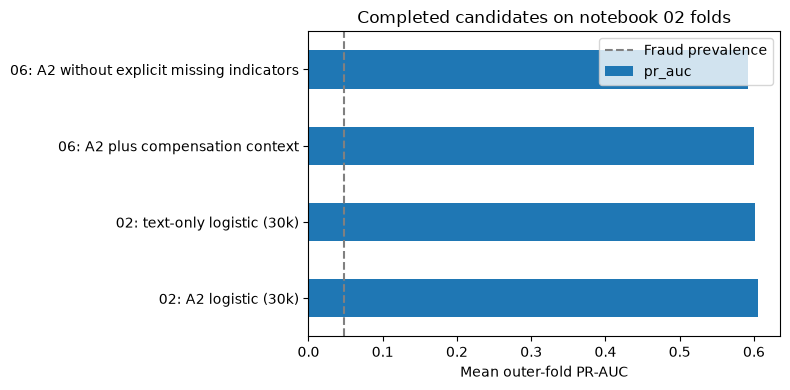

In [9]:
missing = [key for key in CANDIDATES if key not in RESULTS]
print('Comparison status:', 'COMPLETE' if not missing else f'PARTIAL — pending {missing}')
summary = pd.DataFrame({NAMES[k]: summarise(v, k) for k, v in RESULTS.items()}).T
summary = summary.sort_values('pr_auc', ascending=False)
display(summary[['pr_auc', 'precision', 'recall', 'f1', 'precision_top5pct', 'recall_top5pct']].round(3))
ax = summary.pr_auc.plot.barh(figsize=(8, 4), xlabel='Mean outer-fold PR-AUC', title='Completed candidates on notebook 02 folds')
ax.axvline(y.mean(), color='grey', linestyle='--', label='Fraud prevalence')
ax.legend()
plt.tight_layout()
plt.show()
REPORT_DIR.mkdir(parents=True, exist_ok=True)
summary.to_csv(REPORT_DIR / 'comparison_summary.csv')

## 4. Paired comparison against both saved baselines

The primary reference for these changes is A2 logistic 30k. The text-only reference provides additional context. Approximate paired intervals are exploratory and not adjusted for all experiments. Inspect precision, recall and review-budget results as well as PR-AUC. Reject the hypothesis if it does not help; do not tune rules repeatedly on the same few errors. The reserved test set stays untouched.

In [10]:
comparisons = []
for key in RESULTS:
    if key in BASELINES:
        continue
    for reference in BASELINES:
        difference = paired_comparison(RESULTS[key], RESULTS[reference], metric='pr_auc')
        comparisons.append({'candidate': NAMES[key], 'reference': NAMES[reference], **difference})
paired = pd.DataFrame(comparisons, columns=['candidate', 'reference', 'mean_diff', 'se', 'low', 'high', 'share_folds_a_better'])
if paired.empty:
    print('Candidate has not completed. Set TRAIN_MODELS in the setup cell when ready.')
else:
    display(paired.round(3))
paired.to_csv(REPORT_DIR / 'paired_differences.csv', index=False)
print('The reserved test set has not been opened.')

,candidate,reference,mean_diff,se,low,high,share_folds_a_better
0,06: A2 without explicit missing indicators,02: text-only logistic (30k),-0.009,0.050,-0.108,0.090,0.48
1,06: A2 without explicit missing indicators,02: A2 logistic (30k),-0.013,0.015,-0.042,0.017,0.28
2,06: A2 plus compensation context,02: text-only logistic (30k),-0.001,0.047,-0.094,0.092,0.48
3,06: A2 plus compensation context,02: A2 logistic (30k),-0.005,0.007,-0.019,0.010,0.32


The reserved test set has not been opened.
